In [50]:
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm
from pathlib import Path
from itertools import product
from mne import (
    set_log_level,
    read_epochs,
    concatenate_epochs,
    pick_channels
)
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.preprocessing import minmax_scale

set_log_level("ERROR")

In [2]:
# access to the paths and settings
settings = utils.load_json("settings.json")
trigger_mapping = utils.load_json("trigger_mapping.json")
trigger_mapping = {int(i): trigger_mapping[i] for i in trigger_mapping.keys()}
dataset_path = Path(settings["dataset_path"])
raw_path = dataset_path.joinpath("MEG", "raw")
proc_path = dataset_path.joinpath("MEG", "processed")
beh_path = dataset_path.joinpath("BEH")

In [ ]:
# load basic data
subject = "sub-701"
beh_files = utils.get_files(beh_path, "*.csv", strings=["main_", subject])
beh_files = [i for i in beh_files if "ses_0" not in i._str]
fif_files = utils.get_files(proc_path, "*.fif", strings=["dots-onset", "realtime", "epo.fif", subject])
fif_files = [i for i in fif_files if "ses_0" not in i._str]
meg_calib_file = utils.get_files(proc_path, "*.json", strings=["meg-calibration", subject])[0]
meg_calib = utils.load_json(meg_calib_file)

behaviour = pd.concat([pd.read_csv(i) for i in beh_files]).reset_index(drop=True)
epochs = concatenate_epochs([read_epochs(i, verbose=False) for i in fif_files], add_offset=True, on_mismatch="ignore", verbose=False)
overlap = np.mean(epochs.events[:,2] == behaviour.trial_trigger.to_numpy()) * 100
print(f"epoch order overlaps in {overlap}%")

/tmp/ipykernel_138117/2460885668.py:11: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs = concatenate_epochs([read_epochs(i, verbose=False) for i in fif_files], add_offset=True, on_mismatch="ignore", verbose=False)


epoch order overlaps in 100.0%


In [7]:
# add confidence percentile within sub conditions
conditions = behaviour.groupby(["coherence_level", "counterfactual_label"]).coherence_level.count().reset_index(name="coh_count")
behaviour["confidence_percentile"] = None
for index, (coherence_level, counterfactual_label, coh_count) in conditions.iterrows():
    local_map = (
        (behaviour.coherence_level == coherence_level) &
        (behaviour.counterfactual_label == counterfactual_label)
    )
    lm_index = local_map.index.to_numpy()[local_map]
    behaviour.loc[lm_index, "confidence_percentile"] = behaviour[local_map].scale_response.rank(pct=True)

In [8]:
exclusion = conditions.loc[conditions.coh_count < 20]
ex_map = [(behaviour.coherence_level == coh) & (behaviour.counterfactual_label == cf_l) for ix, (coh, cf_l, cc) in exclusion.iterrows()]
exclusion_map = np.any(np.array([i.to_numpy() for i in ex_map]), axis=0)

In [9]:
# data selections
left_channels = [i for i in epochs.ch_names if "ML" in i]
right_channels = [i for i in epochs.ch_names if "MR" in i]
left_channels_ix = pick_channels(epochs.ch_names, left_channels)
right_channels_ix = pick_channels(epochs.ch_names, right_channels)

gripper_channels = [i for i in epochs.ch_names if "UADC" in i]
gripper_channels_ix = pick_channels(epochs.ch_names, gripper_channels)


# binary labels
response_labels = {
    "is_left": np.array(behaviour.response_key == "left").astype(int),
    "is_right": np.array(behaviour.response_key == "right").astype(int)
}

gripper_mapping = {
    "UADC009": "left",
    "UADC010": "right"
}

resp_gripper_mapping = {
    "left": "UADC009",
    "right": "UADC010"
}

event_timing = {
    0.0: "dots\non",
    0.35: "dots\noff",
    0.6: "scale\non",
    3.1: "scale\noff",
}

ch_resp = list(product(gripper_channels, list(response_labels.keys())))

In [10]:
# gripper data
gripper_data = {}
for gripper_ch in gripper_channels:
    data = epochs.get_data()[:, pick_channels(epochs.ch_names, [gripper_ch])][:,0,:]
    data = (data - meg_calib[gripper_ch][0]) / meg_calib[gripper_ch][1] * 100
    gripper_data[gripper_ch] = data

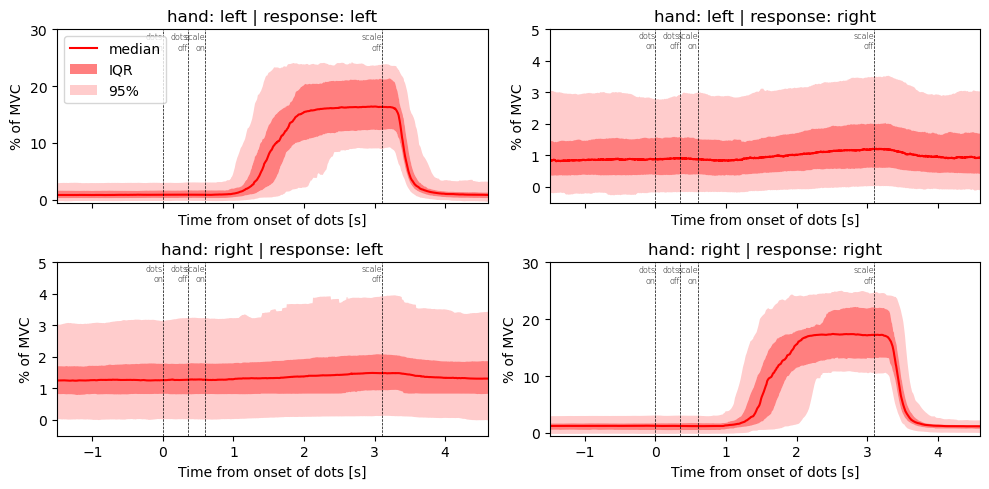

In [73]:
f, axes = plt.subplots(2, 2, figsize=(10, 5), sharex=True)

axes = axes.flatten()

for ix, ax in enumerate(axes):
    gripper_ch, response_side = ch_resp[ix]
    ax.set_title(f"hand: {gripper_mapping[gripper_ch]} | response: {response_side.replace("is_", "")}")
    ax.set_ylabel("% of MVC")
    ax.set_xlabel("Time from onset of dots [s]")
    ax.set_xlim(epochs.times[0], epochs.times[-1])
    if gripper_mapping[gripper_ch] == response_side.replace("is_", ""):
        ymax = 30
        ax.set_ylim(-0.5, ymax)
    else:
        ymax = 5.0
        ax.set_ylim(-0.5, ymax)
    data = gripper_data[gripper_ch][response_labels[response_side].astype(bool)]
    median = np.median(data, axis=0)
    iqr_25 = np.percentile(data, 25, axis=0)
    iqr_75 = np.percentile(data, 75, axis=0)
    iqr_025 = np.percentile(data, 2.5, axis=0)
    iqr_975 = np.percentile(data, 97.5, axis=0)

    ax.plot(epochs.times, median, label="median", c="red")
    ax.fill_between(epochs.times, iqr_25, iqr_75, color="red", lw=0, alpha=0.5, label="IQR")
    ax.fill_between(epochs.times, iqr_025, iqr_25, color="red", lw=0, alpha=0.2)
    ax.fill_between(epochs.times, iqr_75, iqr_975, color="red", lw=0, alpha=0.2, label="95%")

    for i in event_timing.keys():
        ax.axvline(i, lw=0.5, c="black", linestyle="dashed")
        ax.text(i, ymax - (ymax*0.12), event_timing[i], ha="right", weight="ultralight", size="xx-small")

axes[0].legend(loc=2, fancybox=True);
plt.tight_layout()
f.savefig("/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/grip_force_summary.svg")

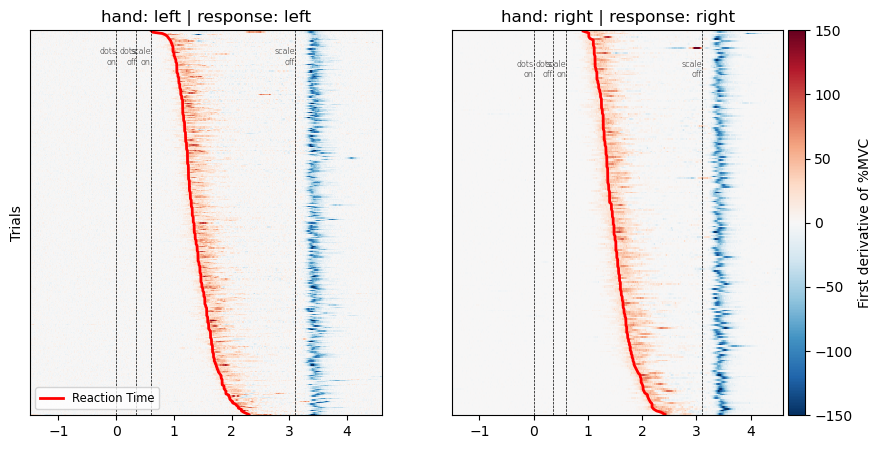

In [ ]:
f, ax = plt.subplots(1,2, figsize=(10, 5), sharey=False)
for col, (sel_label, chan) in enumerate([["is_left", "UADC009"], ["is_right", "UADC010"]]):
    selection = response_labels[sel_label].astype(bool)
    data = gripper_data[chan][selection]
    rts = behaviour[selection].rt.reset_index(drop=True).to_numpy()
    rts_order = np.argsort(rts)
    # data_processed = (data - data.min()) / data.max()
    data_processed = np.gradient(data, epochs.times, axis=1)

    norm = TwoSlopeNorm(
        0, -150, 150
    )

    data_processed_sorted = data_processed[rts_order]
    trial_len = len(rts_order)
    IM = ax[col].imshow(data_processed_sorted, aspect="auto", interpolation="none", norm=norm, cmap="RdBu_r", extent=[epochs.times[0], epochs.times[-1], trial_len, 0])
    if col == 1:
        utils.colorbar(IM, "First derivative of %MVC")
    ax[col].plot(rts[rts_order] + 0.6, np.arange(trial_len) + 0.5, lw=2, c="red", label="Reaction Time")

    for i in event_timing.keys():
        ax[col].axvline(i, lw=0.5, c="black", linestyle="dashed")
        ax[col].text(i, ymax - (ymax*0.12), event_timing[i], ha="right", weight="ultralight", size="xx-small")
    ax[col].set_title(f"hand: {gripper_mapping[chan]} | response: {sel_label.replace("is_", "")}")
    ax[col].set_yticks([])

    # ax[col].
ax[0].set_ylabel("Trials")
ax[0].legend(fontsize="small", loc=3, fancybox=True)
plt.tight_layout;
f.savefig("/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/grip_force_derivative_RT.svg")